# Let Quantum Neural Networks Choose Their Own Frequencies — a reproduction

*Jaderberg, Gentile, Achari Berrada, Shishenina, Elfving, Phys. Rev. A 109, 042421 (2024),
[arXiv:2309.03279](https://arxiv.org/abs/2309.03279).*

This notebook is the entry point of the reproduction in `papers/trainable_frequency_qnn/`.
It tells the story as a scientific argument: what the paper claims, how we tested it, which
controls could explain the result another way, and what survived.

**How to read the evidence labels**

| Label | Meaning |
|---|---|
| `live` | computed in this notebook, now |
| `paper-accurate` | stored runs with the paper's settings and ≥ 3 seeds (loaded from `results/`) |
| `control` | an experiment we added to test an alternative explanation |
| `preliminary` | single or 3-seed evidence |
| `context` | classical model, not matched in circuit resources; not a test of any paper claim |
| `adaptation` | MerLin photonic version: our design, not the paper's model |

Runtime: about 5 minutes on a laptop CPU. Expensive experiments (Navier–Stokes, 10-seed sweeps,
~1000 runs in total) are **loaded** from curated records; the notebook says each time which
conclusions rest on live runs and which on stored runs.

**Contents**
1. Problem statement and claims · 2. Data, metrics and protocol · 3. Why encodings fix frequencies ·
4. Known-answer sanity checks · 5. The three models · 6. Live experiment · 7. Headline results ·
8. Fair baseline comparison · 9. Controls and ablations · 10. Robustness and uncertainty ·
11. Photonic (MerLin) adaptation · 12. Limitations · 13. Conclusion

In [1]:
import json
import math
import shutil
import sys
import time
from copy import deepcopy
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from scipy.stats import wilcoxon

PAPER_DIR = Path.cwd().resolve()
if not (PAPER_DIR / "lib" / "runner.py").is_file():
    raise RuntimeError("Run this notebook from papers/trainable_frequency_qnn/.")
REPO_ROOT = PAPER_DIR.parents[1]
for import_root in (str(REPO_ROOT), str(PAPER_DIR.parent)):
    if import_root not in sys.path:
        sys.path.insert(0, import_root)

# The imports below need the repository and papers/ on sys.path (set just above).
from IPython.display import Image, display  # noqa: E402

from runtime_lib.config import deep_update, load_config  # noqa: E402
from runtime_lib.dtypes import resolve_config_dtypes  # noqa: E402

# Reusable implementation: everything scientific comes from lib/.
from trainable_frequency_qnn.lib.data import (  # noqa: E402
    build_dataset,
    cosine_series_points,
    load_cylinder_wake,
    nyquist_point_count,
)
from trainable_frequency_qnn.lib.experiment_logging import configure_logging  # noqa: E402
from trainable_frequency_qnn.lib.models import build_network, parameter_summary  # noqa: E402
from trainable_frequency_qnn.lib.navier_stokes import maerm  # noqa: E402
from trainable_frequency_qnn.lib.qnn_merlin import PhotonicFrequencyModel  # noqa: E402
from trainable_frequency_qnn.lib.runner import train_and_evaluate  # noqa: E402
from trainable_frequency_qnn.lib.spectrum import (  # noqa: E402
    accessible_frequencies,
    dominant_frequencies,
    prediction_spectrum,
)

torch.set_num_threads(4)
RESULTS = PAPER_DIR / "results"
LIVE_DIR = PAPER_DIR / "outdir" / "notebook"   # disposable, git-ignored
PER_SEED = json.loads((RESULTS / "per_seed_metrics.json").read_text())
COMPARISON = json.loads((RESULTS / "p5_comparison.json").read_text())

# One colour per model family, used in every figure.
COLORS = {"FF": "#eb6834", "FF+S": "#eda100", "TF": "#2a78d6", "classical": "#8a8a85",
          "deep FF": "#9a4f1f", "tower": "#1baf7a", "exponential": "#e87ba4"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


def load_cfg(overlay=None, **updates):
    # defaults.json + configs/<overlay> + updates, as the shared runtime resolves them.
    cfg = load_config(PAPER_DIR / "configs" / "defaults.json")
    if overlay:
        cfg = deep_update(cfg, load_config(PAPER_DIR / "configs" / overlay))
    cfg = deep_update(cfg, updates)
    cfg["data_root"] = None
    return resolve_config_dtypes(cfg)


def run_live(overlay, name, **updates):
    # One full run through lib.runner.train_and_evaluate; artifacts in outdir/notebook/<name>.
    run_dir = LIVE_DIR / name
    shutil.rmtree(run_dir, ignore_errors=True)
    configure_logging(run_dir / "run.log", console=False)   # keep the notebook quiet
    return train_and_evaluate(load_cfg(overlay, **updates), run_dir)


def seeds_of(sweep, candidate, metric):
    # {seed: value} from the curated per-seed export of the stored sweeps.
    runs = PER_SEED[sweep]["candidates"][candidate]
    return {int(seed): row[metric] for seed, row in runs.items()}


def paired(first, second):
    # Paired comparison on common seeds: mean difference, sign count, Wilcoxon p (n >= 5).
    seeds = sorted(set(first) & set(second))
    diff = np.array([first[s] - second[s] for s in seeds])
    p = wilcoxon(diff).pvalue if len(seeds) >= 5 else float("nan")
    return {"n": len(seeds), "mean_a": np.mean([first[s] for s in seeds]),
            "mean_b": np.mean([second[s] for s in seeds]),
            "a_lower": int((diff < 0).sum()), "wilcoxon_p": p}


print("torch", torch.__version__, "| float64 CPU | paper folder:", PAPER_DIR.name)

torch 2.12.1 | float64 CPU | paper folder: trainable_frequency_qnn


## 1. Problem statement and the paper's claims

A quantum neural network (QNN) that encodes an input $x$ through rotation gates computes a
**truncated Fourier series** in $x$. Which frequencies can appear is fixed by the encoding: with
$N$ gates $R_y(x)$ the model can only represent the integer frequencies $\{1, \dots, N\}$
(Schuld et al. 2021). Training changes the coefficients, never the frequencies.

The paper proposes **trainable-frequency (TF)** encodings: replace $R_y(x)$ by $R_y(\theta_m x)$
with trainable $\theta_m$, initialised at 1. A TF model therefore *starts* as the usual
**fixed-frequency (FF)** model and can move its spectrum during training, at the cost of one
extra parameter per encoding gate.

| ID | Claim (paper) | Paper evidence | Where tested here |
|---|---|---|---|
| C1 | FF cannot fit data with irregular frequencies {1, 1.2, 3}, even deeper or with a global input scale; TF can, by learning θ ≈ {0.89, 1.05, 1.04} | Fig. 2, Sec. V | §6, §7.1, §9 |
| C2 | FF fits data whose frequencies match its own gaps ({1, 2, 3}, or a multiple with a global scale) | Fig. 2a, Sec. V | §4, §9 |
| C3 | When the number of data frequencies is unknown, TF beats simple / tower / exponential FF maps in mean and worst-case error | Fig. 3 | §9.3 |
| C4 | On a physics-informed Navier–Stokes solve, TF lowers the error of u, v and p versus the same FF model | Table I, Fig. 4 | §7.2, §8, §9.4 |
| C5 | The same holds for an over-parameterised model | Table II, App. C | §7.2, §9.4 |
| C6 | The overhead is small: $C_f = (12+180)/180 = 1.07$ circuit evaluations | Sec. VI | §10.3 |
| C7 | TF contains FF, so TF is a sensible default that should not do worse | Abstract | §10, §13 |

**Falsifiable research question.** *Does making the encoding frequencies trainable improve a
QNN's fit or accuracy over the same fixed-frequency circuit, beyond what a trainable input
rescaling, more depth, or a better input normalisation would give?*

**What would weaken the claim:** (i) TF not better than FF across paired seeds;
(ii) an FF model with one trainable input scale (FF+S) or with more layers matching TF;
(iii) the TF gain disappearing once inputs are normalised; (iv) TF worse than FF under a
reasonable change of learning rate.

**Not claimed by the paper:** any advantage over classical models. We still show a classical
reference as `context`.

## 2. Data, splits, metrics and evaluation protocol

### 2.1 Toy regression (Figs. 2–3)

The paper's own synthetic data: a noiseless cosine series
$y(x) = \frac{1}{|\Omega_d|}\sum_{\omega\in\Omega_d}\cos(\omega x)$ on $x\in[-4\pi, 4\pi]$,
sampled at $n_d = \lceil 2\,|D|\,\max\Omega_d \rceil$ equally spaced points (Nyquist-like).
There is **no held-out split**: these tasks measure whether a model *can represent* the
function. We also report the MSE on a 4× denser grid of the same interval (our addition) to
check the fit between training points.

Omega_d = [1.0, 1.2, 3.0]: 151 training points, 604 dense points


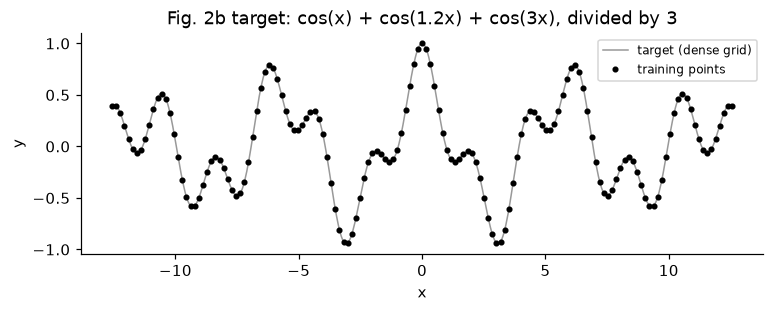

In [2]:
frequencies = [1.0, 1.2, 3.0]
n_train = nyquist_point_count(frequencies, [-4, 4])
x_train, y_train = cosine_series_points(frequencies, [-4, 4], n_train)
x_dense, y_dense = cosine_series_points(frequencies, [-4, 4], 4 * n_train)
print(f"Omega_d = {frequencies}: {n_train} training points, {4 * n_train} dense points")

fig, ax = plt.subplots(figsize=(8, 2.6))
ax.plot(x_dense, y_dense, color="0.6", lw=1, label="target (dense grid)")
ax.plot(x_train, y_train, "o", ms=3, color="k", label="training points")
ax.set(xlabel="x", ylabel="y", title="Fig. 2b target: cos(x) + cos(1.2x) + cos(3x), divided by 3")
ax.legend(loc="upper right", fontsize=8)
plt.show()

### 2.2 Navier–Stokes (Table I, Fig. 4, App. C)

The original cylinder-wake simulation at Reynolds number 100 (Raissi et al., NekTar FEM),
`data/trainable_frequency_qnn/cylinder_nektar_wake/cylinder_nektar_wake.mat`, pinned to commit
`932f50a` of the authors' repository (download command in `README.md`). Two QNNs output the
stream function ψ and the pressure p; velocities come from derivatives of ψ. The loss is the
**incompressible Navier–Stokes residual** at random collocation points (third-order input
derivatives) plus a data term on a 10 × 5 sub-grid, i.e. **1 % of the spatial grid**.
Evaluation uses the **full** 100 × 50 grid at every time step, so 99 % of evaluation points are
never seen by the data loss.

In [3]:
ns_cfg = load_cfg("ns_table1_tf_original.json")
wake = load_cylinder_wake(ns_cfg)
data_rows = len(build_dataset(ns_cfg, "data"))
print(f"grid points: {wake['x'].size} (x in [{wake['x'].min():.0f}, {wake['x'].max():.0f}], "
      f"y in [{wake['y'].min():.0f}, {wake['y'].max():.0f}]), "
      f"time steps in [0, 5.5]: {wake['t'].size}")
print(f"data-loss points (sub-grid x all times): {data_rows} "
      f"= {data_rows / (wake['x'].size * wake['t'].size):.1%} of space-time points")
print("evaluation times (Table I):", ns_cfg["dataset"]["evaluation_times"])

grid points: 5000 (x in [1, 8], y in [-2, 2]), time steps in [0, 5.5]: 56
data-loss points (sub-grid x all times): 2800 = 1.0% of space-time points
evaluation times (Table I): [0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0, 5.5]


**Metric — MAERM.** Mean absolute error relative to the median, per time step, in percent:
$\mathrm{MAERM} = 100\,\overline{|\hat y - y|}\,/\,\mathrm{median}(|y|)$. Table I reports the
min / max / mean over $t = 0.5, 1.0, \dots, 5.5$. The paper writes "median of $y$"; for
$v$, whose signed median is ≈ 0, that definition explodes, so we use median(|y|). This choice
reproduces the paper's TF $v$ error exactly (30.4 %), which pins it (deviation A10).

In [4]:
# Known answer: a constant 10 % error on a field with median |y| = 1 gives MAERM = 10 %.
reference = np.array([-2.0, -1.0, 1.0, 1.0, 3.0])
print(maerm(reference + 0.1, reference))    # maerm_abs_median = 10.0
# On a field whose signed median is ~0 (like v), the literal definition blows up:
print(maerm(np.array([-1.0, 0.01, 1.0]) + 0.1, np.array([-1.0, 0.01, 1.0])))

{'maerm': 10.000000000000005, 'maerm_abs_median': 10.000000000000005}
{'maerm': 1000.0000000000002, 'maerm_abs_median': 10.000000000000002}


### 2.3 Protocol (identical for every compared model)

| Item | Toy tasks | Navier–Stokes |
|---|---|---|
| Optimiser | Adam, lr $10^{-3}$ | Adam, lr $10^{-2}$ |
| Iterations / batch | 2000–6000 / 1–2 points | 5000 / 600 collocation + 600 data points |
| Checkpoint | final iteration | final iteration |
| Seeds | 10 paired (Fig. 2), 5 per dataset (Fig. 3) | 10 paired (TF, FF), 5 (controls) |
| Selection | none: paper hyperparameters, no per-model tuning | same |
| Metric (lower is better) | train MSE (dense MSE alongside) | mean MAERM for u, v, p |

**Paired seeds.** One seeded generator draws the ansatz angles *before* any frequency parameter
exists, so FF, FF+S and TF runs with the same seed start from the identical circuit. We can
therefore compare models seed by seed.

**Decision rule** (frozen before the comparison table was generated):
5 % relative tie tolerance; "TF lower" needs ≥ 80 % of paired seeds lower and a Wilcoxon
signed-rank $p<0.05$. With 5 seeds the smallest possible two-sided $p$ is 0.0625, so a 5/5
result is reported as **consistent**, not significant.

## 3. Why the encoding fixes the frequencies

The model is $f(x) = \langle 0|\,U^\dagger(x)\,M\,U(x)\,|0\rangle$ where $U(x)$ alternates
trainable layers with encoding blocks $\bigotimes_m R_y(w_m x) = \exp(-\tfrac{i}{2}x\sum_m w_m Y_m)$.
Each $R_y(w_m x)$ has eigenvalues $\pm w_m/2$, so $f(x)$ is a Fourier series whose frequencies are
the **differences of generator eigenvalues**: every $\sum_m c_m w_m$ with $c_m\in\{-1,0,1\}$.

* **FF** ($w_m = 1$, $N = 3$): frequencies $\{1, 2, 3\}$ — regularly spaced integers.
* **TF** (trainable $w_m$): the same combinatorics with learned weights, so non-integer and
  irregular gaps become reachable.
* **FF+S** (our control): FF with one trainable global scale $s$, $w_m = s$: frequencies
  $\{s, 2s, 3s\}$ — still regularly spaced.

`lib.spectrum.accessible_frequencies` enumerates these sets:

In [5]:
for name, weights in [("FF", [1, 1, 1]), ("FF+S, s = 1.2", [1.2, 1.2, 1.2]),
                      ("TF, paper's learned θ", [0.89, 1.05, 1.04])]:
    print(f"{name:24s} → {accessible_frequencies(weights, decimals=3)}")

FF                       → [1, 2, 3]
FF+S, s = 1.2            → [1.2, 2.4, 3.6]
TF, paper's learned θ    → [0.01, 0.15, 0.16, 0.88, 0.89, 0.9, 1.04, 1.05, 1.2, 1.93, 1.94, 2.09, 2.98]


FF can never contain both 1 and 1.2. FF+S can contain 1.2 but then not 1 or 3. The paper's
learned TF weights give a set that contains 1.2 exactly (1.05 + 1.04 − 0.89), frequencies
close to 1 (0.88–0.90, 1.04–1.05) and to 3 (2.98), plus extra ones the model must suppress
(0.15, 1.93, …). Whether training finds such weights and fits the target is an empirical
question (§6).

## 4. Known-answer sanity checks

Before trusting any result, we check the simulator against cases whose answer is known.
For speed, `lib/qnn.py` evaluates circuits in the Pauli-Y eigenbasis with fused layers (58×
faster than gate by gate); check (a) shows it is exact.

In [6]:
toy_cfg = load_cfg("fig2b_tf_original.json")
dtype = torch.float64
inputs = torch.linspace(-4 * math.pi, 4 * math.pi, 64, dtype=dtype)[:, None]


def toy_model(frequency_mode, seed=1, overlay="fig2b_tf_original.json"):
    model_cfg = deep_update(deepcopy(load_cfg(overlay)["model"]), {"frequency_mode": frequency_mode})
    return build_network(model_cfg, 1, dtype, torch.Generator().manual_seed(seed))


# (a) fused evaluation == literal gate-by-gate circuit
model = toy_model("trainable")
with torch.no_grad():
    gap = (model(inputs) - model.forward_gatewise(inputs)).abs().max().item()
print(f"(a) fused vs gate-by-gate: max |difference| = {gap:.1e}")
assert gap < 1e-10

# (b) an untrained FF model contains only the frequencies {1, 2, 3}
#     (a finite DFT window leaks ~1e-4 of the peak height to every bin; true extra
#     frequencies would appear as peaks of order 1e-1)
angular, magnitude = prediction_spectrum(toy_model("fixed"), 64, 16384, dtype, "cpu")
peaks = dominant_frequencies(angular, magnitude, 3)
above = magnitude[angular > 3.2].max() / magnitude.max()
print(f"(b) FF spectrum peaks: {[round(w, 3) for w in peaks]}; "
      f"largest relative magnitude above ω = 3.2: {above:.1e} (window leakage level)")
assert all(abs(w - round(w)) < 2 * (angular[1] - angular[0]) for w in peaks) and above < 1e-3

# (c) paired seeds: FF, FF+S and TF with the same seed are the same function at initialisation
with torch.no_grad():
    outputs = [toy_model(mode)(inputs) for mode in ("fixed", "global_scale", "trainable")]
print(f"(c) max |TF - FF| at init = {(outputs[2] - outputs[0]).abs().max():.1e}, "
      f"max |FF+S - FF| = {(outputs[1] - outputs[0]).abs().max():.1e}")
assert torch.allclose(outputs[0], outputs[2]) and torch.allclose(outputs[0], outputs[1])

(a) fused vs gate-by-gate: max |difference| = 1.8e-15
(b) FF spectrum peaks: [1.0, 2.0, 3.0]; largest relative magnitude above ω = 3.2: 2.1e-04 (window leakage level)
(c) max |TF - FF| at init = 0.0e+00, max |FF+S - FF| = 0.0e+00


Further known-answer tests live in `tests/` (run `pytest -q`, 44 tests): analytic
Navier–Stokes residuals of a known flow, autograd vs finite-difference third derivatives,
and the photonic spectrum checks used in §11. In the stored runs, a model whose target is
reachable fits it to $10^{-10}$–$10^{-11}$ (Fig. 3 with k ≤ 3; §9.2), which rules out
gross optimisation or implementation errors.

## 5. The three models we compare

All three share the paper's circuit for Fig. 2: $N = 3$ qubits, 4 layers of
$R_xR_yR_x$ + CNOT ring, the encoding $\bigotimes_m R_y(w_m x)$ re-uploaded before each layer,
and the observable $\sum_m Z_m$. They differ **only** in the encoding weights:

In [7]:
rows = []
for label, mode in [("FF (paper baseline)", "fixed"), ("FF+S (our control)", "global_scale"),
                    ("TF (paper's method)", "trainable")]:
    model = toy_model(mode)
    summary = parameter_summary(model)
    rows.append((label, summary["ansatz"], summary["frequency"], summary["total"],
                 [round(w, 3) for w in model.encoding_frequencies().tolist()]))
print(f"{'model':22s} {'ansatz':>6s} {'freq.':>6s} {'total':>6s}  encoding weights at init")
for label, ansatz, freq, total, weights in rows:
    print(f"{label:22s} {ansatz:6d} {freq:6d} {total:6d}  {weights}")

model                  ansatz  freq.  total  encoding weights at init
FF (paper baseline)        36      0     36  [1.0, 1.0, 1.0]
FF+S (our control)         36      1     37  [1.0, 1.0, 1.0]
TF (paper's method)        36      3     39  [1.0, 1.0, 1.0]


TF has 3 more parameters than FF (39 vs 36, +8 %); FF+S has 1. Navier–Stokes uses the same
idea with two 6-qubit networks (180 ansatz parameters each; TF +6, FF+S +3 per network) and a
parallel encoding of $(x, y, t)$ — 2 qubits per coordinate.

## 6. Live experiment: Fig. 2b with the paper's settings  `live`

We train FF, FF+S and TF on {1, 1.2, 3} with the paper's App. B settings (6000 iterations,
batch 2, Adam lr $10^{-3}$) for **seeds 1–3**, through the same entry point the stored sweeps
used (`lib.runner.train_and_evaluate`). Nine runs, about 1–2 minutes.

In [8]:
LIVE_SEEDS = (1, 2, 3)
LIVE_MODELS = {"FF": "fig2b_ff_original.json", "FF+S": "fig2b_ffs_original.json",
               "TF": "fig2b_tf_original.json"}
live = {name: {} for name in LIVE_MODELS}
started = time.perf_counter()
for name, overlay in LIVE_MODELS.items():
    for seed in LIVE_SEEDS:
        live[name][seed] = run_live(overlay, f"e2_{name.replace('+', 'p')}_seed{seed}", seed=seed)
print(f"9 runs in {time.perf_counter() - started:.0f} s")

print(f"\n{'model':6s} " + " ".join(f"seed {s:>2d}  " for s in LIVE_SEEDS) + "  mean train MSE")
for name in LIVE_MODELS:
    values = [live[name][s]["train_mse"] for s in LIVE_SEEDS]
    print(f"{name:6s} " + " ".join(f"{v:9.2e}" for v in values) + f"   {np.mean(values):.2e}")

9 runs in 96 s

model  seed  1   seed  2   seed  3    mean train MSE
FF      5.05e-02  5.05e-02  5.08e-02   5.06e-02
FF+S    4.86e-02  6.49e-02  4.87e-02   5.40e-02
TF      9.98e-04  3.27e-04  3.36e-04   5.54e-04


In [9]:
# Reproducibility check: the live runs must equal the stored sweep runs with the same seeds.
stored_name = {"FF": "ff", "FF+S": "ffs", "TF": "tf"}
worst = max(abs(live[n][s]["train_mse"] / seeds_of("e2_fig2b", stored_name[n], "train_mse")[s] - 1)
            for n in LIVE_MODELS for s in LIVE_SEEDS)
print(f"max relative difference live vs stored (9 runs): {worst:.1e}")
assert worst < 1e-6

max relative difference live vs stored (9 runs): 0.0e+00


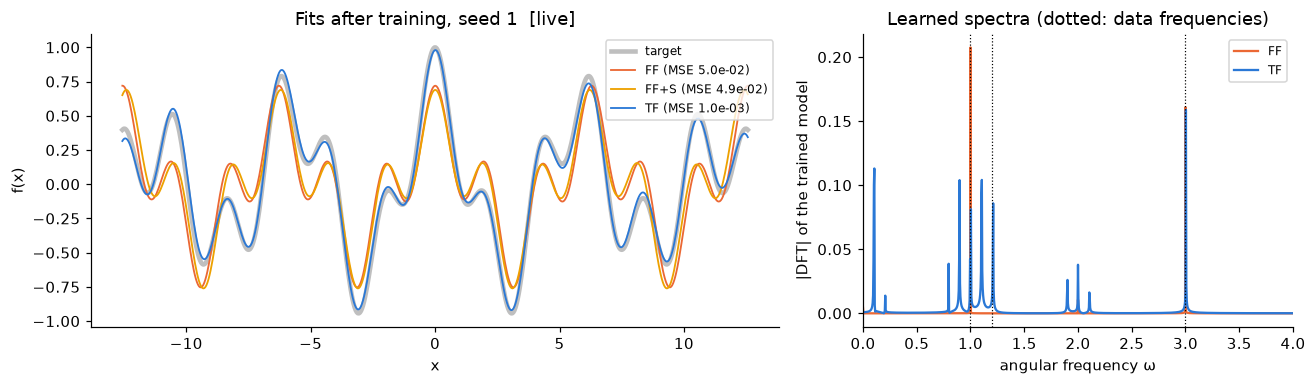

learned TF weights θ_F (sorted):
  seed 1: [0.897, 1.003, 1.104]   (paper: [0.89, 1.04, 1.05])
  seed 2: [0.925, 0.927, 1.15]   (paper: [0.89, 1.04, 1.05])
  seed 3: [0.896, 1.042, 1.067]   (paper: [0.89, 1.04, 1.05])


In [10]:
def load_predictions(name, seed):
    return np.load(LIVE_DIR / f"e2_{name.replace('+', 'p')}_seed{seed}" / "predictions.npz")


fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
ax.plot(x_dense, y_dense, color="0.75", lw=3, label="target")
for name in LIVE_MODELS:
    pred = load_predictions(name, 1)
    ax.plot(pred["dense_x"], pred["dense_prediction"], color=COLORS[name], lw=1.2,
            label=f"{name} (MSE {live[name][1]['train_mse']:.1e})")
ax.set(xlabel="x", ylabel="f(x)", title="Fits after training, seed 1  [live]")
ax.legend(fontsize=8, loc="upper right")

ax = axes[1]
for name in ("FF", "TF"):
    spectrum = np.load(LIVE_DIR / f"e2_{name}_seed1" / "spectrum.npz")
    ax.plot(spectrum["angular_frequency"], spectrum["magnitude"], color=COLORS[name], label=name)
for w in frequencies:
    ax.axvline(w, color="k", ls=":", lw=0.8)
ax.set(xlim=(0, 4), xlabel="angular frequency ω", ylabel="|DFT| of the trained model",
       title="Learned spectra (dotted: data frequencies)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print("learned TF weights θ_F (sorted):")
for seed in LIVE_SEEDS:
    print(f"  seed {seed}: {sorted(round(w, 3) for w in live['TF'][seed]['encoding_multipliers'])}"
          f"   (paper: [0.89, 1.04, 1.05])")

**Observation.** FF and FF+S stay at train MSE ≈ 0.05 and their spectra sit on 1, 2, 3. TF
reaches ≈ $10^{-3}$, puts power at ≈ 1.2, and learns one weight near 0.9 and two near
1.0–1.1, like the paper. The live runs equal the stored sweep runs to < $10^{-6}$.

**Inference.** The FF failure is structural: its frequency set cannot contain 1 and 1.2
together, and one global scale (FF+S) cannot fix that, exactly as §3 predicts.

**Remaining uncertainty.** Three seeds here; the 10-seed result follows in §7.1. These are
representational fits (no held-out data).

**Claim impact (C1).** Reproduced live.

## 7. Headline reproduction results  `paper-accurate`

### 7.1 Fig. 2b with 10 paired seeds (stored)

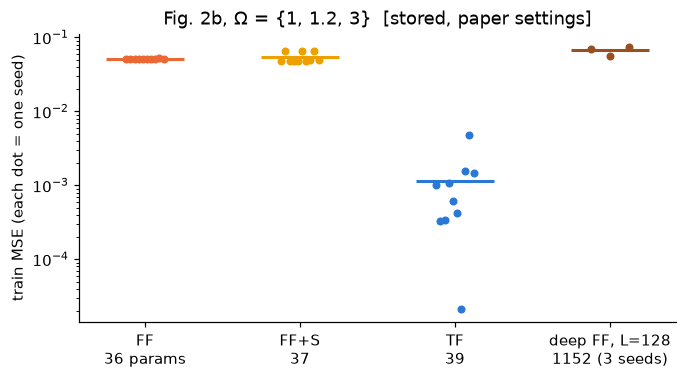

TF vs FF  : mean 1.16e-03 vs 5.08e-02, TF lower in 10/10 seeds, Wilcoxon p = 0.002
TF vs FF+S: mean 1.16e-03 vs 5.37e-02, TF lower in 10/10 seeds, Wilcoxon p = 0.002
TF (39 params) vs FF with L = 128 (1152 params): 1.16e-03 vs 6.70e-02


In [11]:
e2 = {label: seeds_of("e2_fig2b", key, "train_mse")
      for label, key in [("FF", "ff"), ("FF+S", "ffs"), ("TF", "tf")]}
deep = seeds_of("e3_ff_depth", "ff_L128", "train_mse")

fig, ax = plt.subplots(figsize=(7, 3.4))
for i, (label, values) in enumerate(list(e2.items()) + [("deep FF (L=128)", deep)]):
    color = COLORS.get(label, COLORS["deep FF"])
    ys = list(values.values())
    ax.scatter(np.full(len(ys), i) + np.linspace(-0.12, 0.12, len(ys)), ys, color=color, s=18)
    ax.hlines(np.mean(ys), i - 0.25, i + 0.25, color=color, lw=2)
ax.set_xticks(range(4), ["FF\n36 params", "FF+S\n37", "TF\n39", "deep FF, L=128\n1152 (3 seeds)"])
ax.set_yscale("log")
ax.set(ylabel="train MSE (each dot = one seed)", title="Fig. 2b, Ω = {1, 1.2, 3}  [stored, paper settings]")
plt.show()

for name in ("FF", "FF+S"):
    r = paired(e2["TF"], e2[name])
    print(f"TF vs {name:4s}: mean {r['mean_a']:.2e} vs {r['mean_b']:.2e}, TF lower in "
          f"{r['a_lower']}/{r['n']} seeds, Wilcoxon p = {r['wilcoxon_p']:.3f}")
print(f"TF (39 params) vs FF with L = 128 (1152 params): {np.mean(list(e2['TF'].values())):.2e} "
      f"vs {np.mean(list(deep.values())):.2e}")

**Observation.** TF is lower than FF and FF+S in 10/10 seeds ($p = 0.002$), by ≈ 40×; an FF
with 32× more layers is no better than the shallow FF.
**Inference.** Neither a global input scale nor capacity explains TF's gain on this task.
**Remaining uncertainty.** Learning rate (checked in §10.1).
**Claim impact (C1).** Reproduced quantitatively, controls included.

### 7.2 Navier–Stokes: Tables I and II (stored, remote NVIDIA L4 host)

Each Navier–Stokes run takes 20–75 minutes, so we load the 10-seed records. A 3-iteration smoke
run shows the pipeline executing live (it is **not** a result).

In [12]:
started = time.perf_counter()
smoke = run_live("ns_table1_tf_smoke_reduced.json", "ns_smoke", seed=1)
print(f"live Navier–Stokes smoke run (3 iterations, `smoke`, not a result): "
      f"{time.perf_counter() - started:.1f} s, final loss {smoke['final_loss']:.3f}, "
      f"parameters {smoke['parameters']['stream']['total']} per network, C_f = {smoke['cost_factor']:.3f}")

PAPER_TABLES = {  # mean MAERM %, mean over the paper's 10 runs
    "Table I": {"FF": (17.5, 103.2, 73.2), "TF": (13.2, 30.4, 57.0)},
    "Table II": {"FF": (7.7, 26.0, 45.2), "TF": (6.2, 18.9, 36.8)},
}
SWEEPS = {"Table I": {"FF": ("e6_table1", "ff"), "TF": ("e6_table1", "tf")},
          "Table II": {"FF": ("e7_appc", "ff"), "TF": ("e7_appc_retry+e7_appc", "tf")}}


def ns_seeds(sweep, candidate, field):
    if "+" in sweep:   # E7 TF: union of the parent sweep (13 runs) and its retry (7 runs)
        merged = {}
        for part in sweep.split("+"):
            for seed, value in seeds_of(part, candidate, f"{field}_mean_maerm").items():
                merged.setdefault(seed, value)
        return merged
    return seeds_of(sweep, candidate, f"{field}_mean_maerm")


print(f"\n{'':9s}{'model':4s} {'paper u / v / p':>22s} {'ours u / v / p (± std, 10 seeds)':>42s}")
for table in PAPER_TABLES:
    for model in ("FF", "TF"):
        ours = [list(ns_seeds(*SWEEPS[table][model], f).values()) for f in "uvp"]
        cells = " / ".join(f"{np.mean(v):5.1f}±{np.std(v, ddof=1):3.1f}" for v in ours)
        paper = " / ".join(f"{v:5.1f}" for v in PAPER_TABLES[table][model])
        print(f"{table:9s}{model:4s} {paper:>22s} {cells:>42s}   n={len(ours[0])}")

live Navier–Stokes smoke run (3 iterations, `smoke`, not a result): 0.6 s, final loss 1.634, parameters 186 per network, C_f = 1.033

         model        paper u / v / p           ours u / v / p (± std, 10 seeds)
Table I  FF     17.5 / 103.2 /  73.2           20.1±0.9 /  61.0±1.8 /  76.2±3.5   n=10
Table I  TF     13.2 /  30.4 /  57.0            9.0±1.4 /  30.4±3.5 /  45.6±3.6   n=10
Table II FF      7.7 /  26.0 /  45.2          31.5±5.4 /  73.2±8.7 / 123.3±13.0   n=10
Table II TF      6.2 /  18.9 /  36.8            6.6±0.9 /  20.1±1.3 /  34.8±2.6   n=10


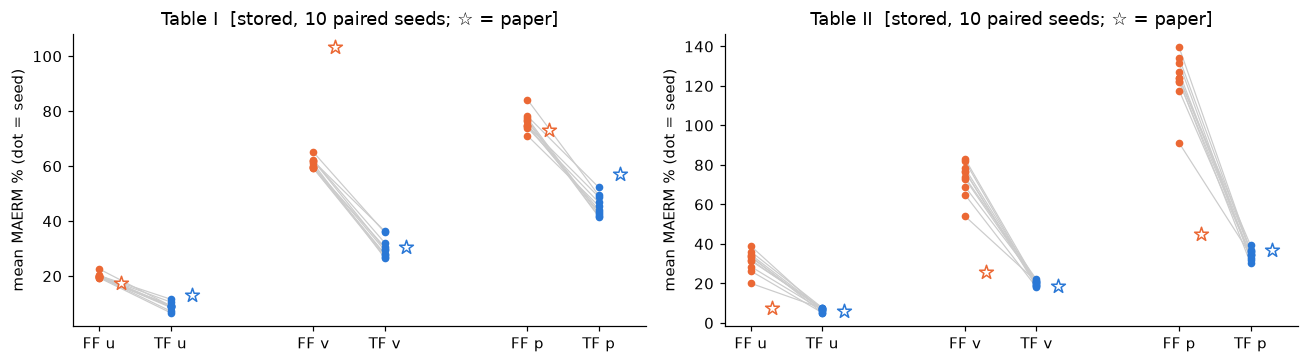

Table I u: TF lower in 10/10 seeds, p = 0.002
Table I v: TF lower in 10/10 seeds, p = 0.002
Table I p: TF lower in 10/10 seeds, p = 0.002
Table II u: TF lower in 10/10 seeds, p = 0.002
Table II v: TF lower in 10/10 seeds, p = 0.002
Table II p: TF lower in 10/10 seeds, p = 0.002


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=False)
for ax, table in zip(axes, PAPER_TABLES):
    for j, field in enumerate("uvp"):
        ff = ns_seeds(*SWEEPS[table]["FF"], field)
        tf = ns_seeds(*SWEEPS[table]["TF"], field)
        for seed in ff:   # one grey line per paired seed
            ax.plot([3 * j, 3 * j + 1], [ff[seed], tf[seed]], color="0.8", lw=0.8, zorder=1)
        ax.scatter([3 * j] * len(ff), list(ff.values()), color=COLORS["FF"], s=16, zorder=2)
        ax.scatter([3 * j + 1] * len(tf), list(tf.values()), color=COLORS["TF"], s=16, zorder=2)
        for k, model in enumerate(("FF", "TF")):
            ax.scatter(3 * j + k + 0.3, PAPER_TABLES[table][model][j], marker="*", s=90,
                       facecolor="white", edgecolor=COLORS[model], zorder=3)
    ax.set_xticks([0, 1, 3, 4, 6, 7], ["FF u", "TF u", "FF v", "TF v", "FF p", "TF p"])
    ax.set(ylabel="mean MAERM % (dot = seed)", title=f"{table}  [stored, 10 paired seeds; ☆ = paper]")
plt.tight_layout()
plt.show()

for table in PAPER_TABLES:
    for field in "uvp":
        r = paired(ns_seeds(*SWEEPS[table]["TF"], field), ns_seeds(*SWEEPS[table]["FF"], field))
        print(f"{table} {field}: TF lower in {r['a_lower']}/{r['n']} seeds, p = {r['wilcoxon_p']:.3f}")

**Observation.** TF beats FF in 10/10 paired seeds for u, v and p in both tables. Our TF matches
the paper closely (Table I v = 30.4 % exactly; Table II within about one seed-std). Our FF
does not: in Table II it is 2.7–4× worse than the paper's FF.

**Inference.** The ranking reproduces. The FF gap in Table II needs an explanation before we
attribute it to trainable frequencies — the diagnosis (§9.4) traces it to raw, unnormalised
input coordinates, which the paper does not specify.

**Remaining uncertainty.** The paper's input normalisation and batch composition (deviations
A7, A8) are unstated, so absolute FF numbers cannot be matched with confidence.

**Claim impact (C4, C5).** Ranking reproduced against the paper's baseline; whether it is
caused by trainable frequencies is tested in §8–9.

Stored figures of the pressure field (Fig. 4 analogue) are in
`results/e6_table1_pressure_t3.5.png` and `results/e7_appc_pressure_t4.0.png`.

## 8. Fair baseline comparison

The paper's baseline — the **identical circuit with frequencies frozen at 1** — is the right
control for its mechanism: it differs from TF only in the trainable weights. We judged it
`FAIR_AND_REPRODUCED` and reused it. But "same circuit" is not "matched on everything", so we
added controls for the obvious alternatives, and a strong conventional (classical) reference.

| Dimension | FF (paper baseline) | FF+S (control) | Deeper FF (control) | Classical MLP / MLP PINN (context) |
|---|---|---|---|---|
| Information and inputs | same raw inputs | same | same | same |
| Parameter count | TF − 3 (toy), − 6 / − 12 per network (NS) | TF − 2 / − 3 per network | up to 1152 (≫ TF's 39) | toy MLP 40 vs 39 (matched ±10 %); NS 188 vs 186 per network |
| Training data | same points, same batch draws | same | same | same |
| Optimisation steps | same | same | same | same |
| Tuning budget | none (paper values) | none | none | toy: paper lr; NS: lr ∈ {1e-3, 1e-2} chosen by final training loss |
| Compute / wall time | same circuit cost | same | ∝ depth | ≈ 5× cheaper per iteration (NS) |
| Evaluation protocol | same | same | same | same |

**Matched:** inputs, data, steps, evaluation. **Not matched:** parameter count (TF has a few
more) and, for the classical model, circuit resources. The classical model is therefore
`context`, not a test of any paper claim.

The full frozen comparison (817 runs, `utils/compare_fair.py` → `results/p5_comparison.md`):

In [14]:
KEEP = {("E2.tf", "E2.ff"), ("E2.tf", "E2.ffs"), ("E2.tf", "E3.ff_L128"), ("E2.tf", "E2.mlp"),
        ("E6.tf", "E6.ff"), ("E6.tf", "E6.ffs"), ("E6.tf_minmax", "E6.ff_minmax"), ("E6.tf", "E6.mlp"),
        ("E7.tf", "E7.ff"), ("E7.tf", "E7.ffs"), ("E7.tf_minmax", "E7.ff_minmax")}
print(f"{'claim':6s} {'A (method)':14s} {'B (baseline)':14s} {'metric':14s} "
      f"{'r=(A-B)/B':>10s} {'A lower':>8s} {'p':>7s}  decision / commensurability")
for row in COMPARISON["comparisons"]:
    if (row["a"], row["b"]) not in KEEP:
        continue
    seeds = f"{row['a_lower_seeds']}/{row['n_paired']}" if row["mode"] == "paired" else "unpaired"
    p = row.get("wilcoxon_p")
    print(f"{row['claim']:6s} {row['a']:14s} {row['b']:14s} {row['metric']:14s} "
          f"{row['relative_difference']:+10.1%} {seeds:>8s} {p if p is not None else float('nan'):7.3f}  "
          f"{row['decision']} / {row['commensurability']}")

claim  A (method)     B (baseline)   metric          r=(A-B)/B  A lower       p  decision / commensurability
C1     E2.tf          E2.ff          train_mse          -97.7%    10/10   0.002  A_LOWER / COMMENSURABLE
C1     E2.tf          E2.ffs         train_mse          -97.8%    10/10   0.002  A_LOWER / COMMENSURABLE
C1     E2.tf          E3.ff_L128     train_mse          -98.3% unpaired     nan  A_LOWER / COMMENSURABLE
C1     E2.tf          E2.mlp         train_mse          -99.2%    10/10   0.002  A_LOWER / PARTIALLY_COMMENSURABLE
C4     E6.tf          E6.ff          u_mean_maerm       -55.2%    10/10   0.002  A_LOWER / COMMENSURABLE
C4     E6.tf          E6.ff          v_mean_maerm       -50.2%    10/10   0.002  A_LOWER / COMMENSURABLE
C4     E6.tf          E6.ff          p_mean_maerm       -40.2%    10/10   0.002  A_LOWER / COMMENSURABLE
C4     E6.tf          E6.ffs         u_mean_maerm       -18.9%      5/5   0.062  A_LOWER_CONSISTENT / COMMENSURABLE
C4     E6.tf          E6.ffs  

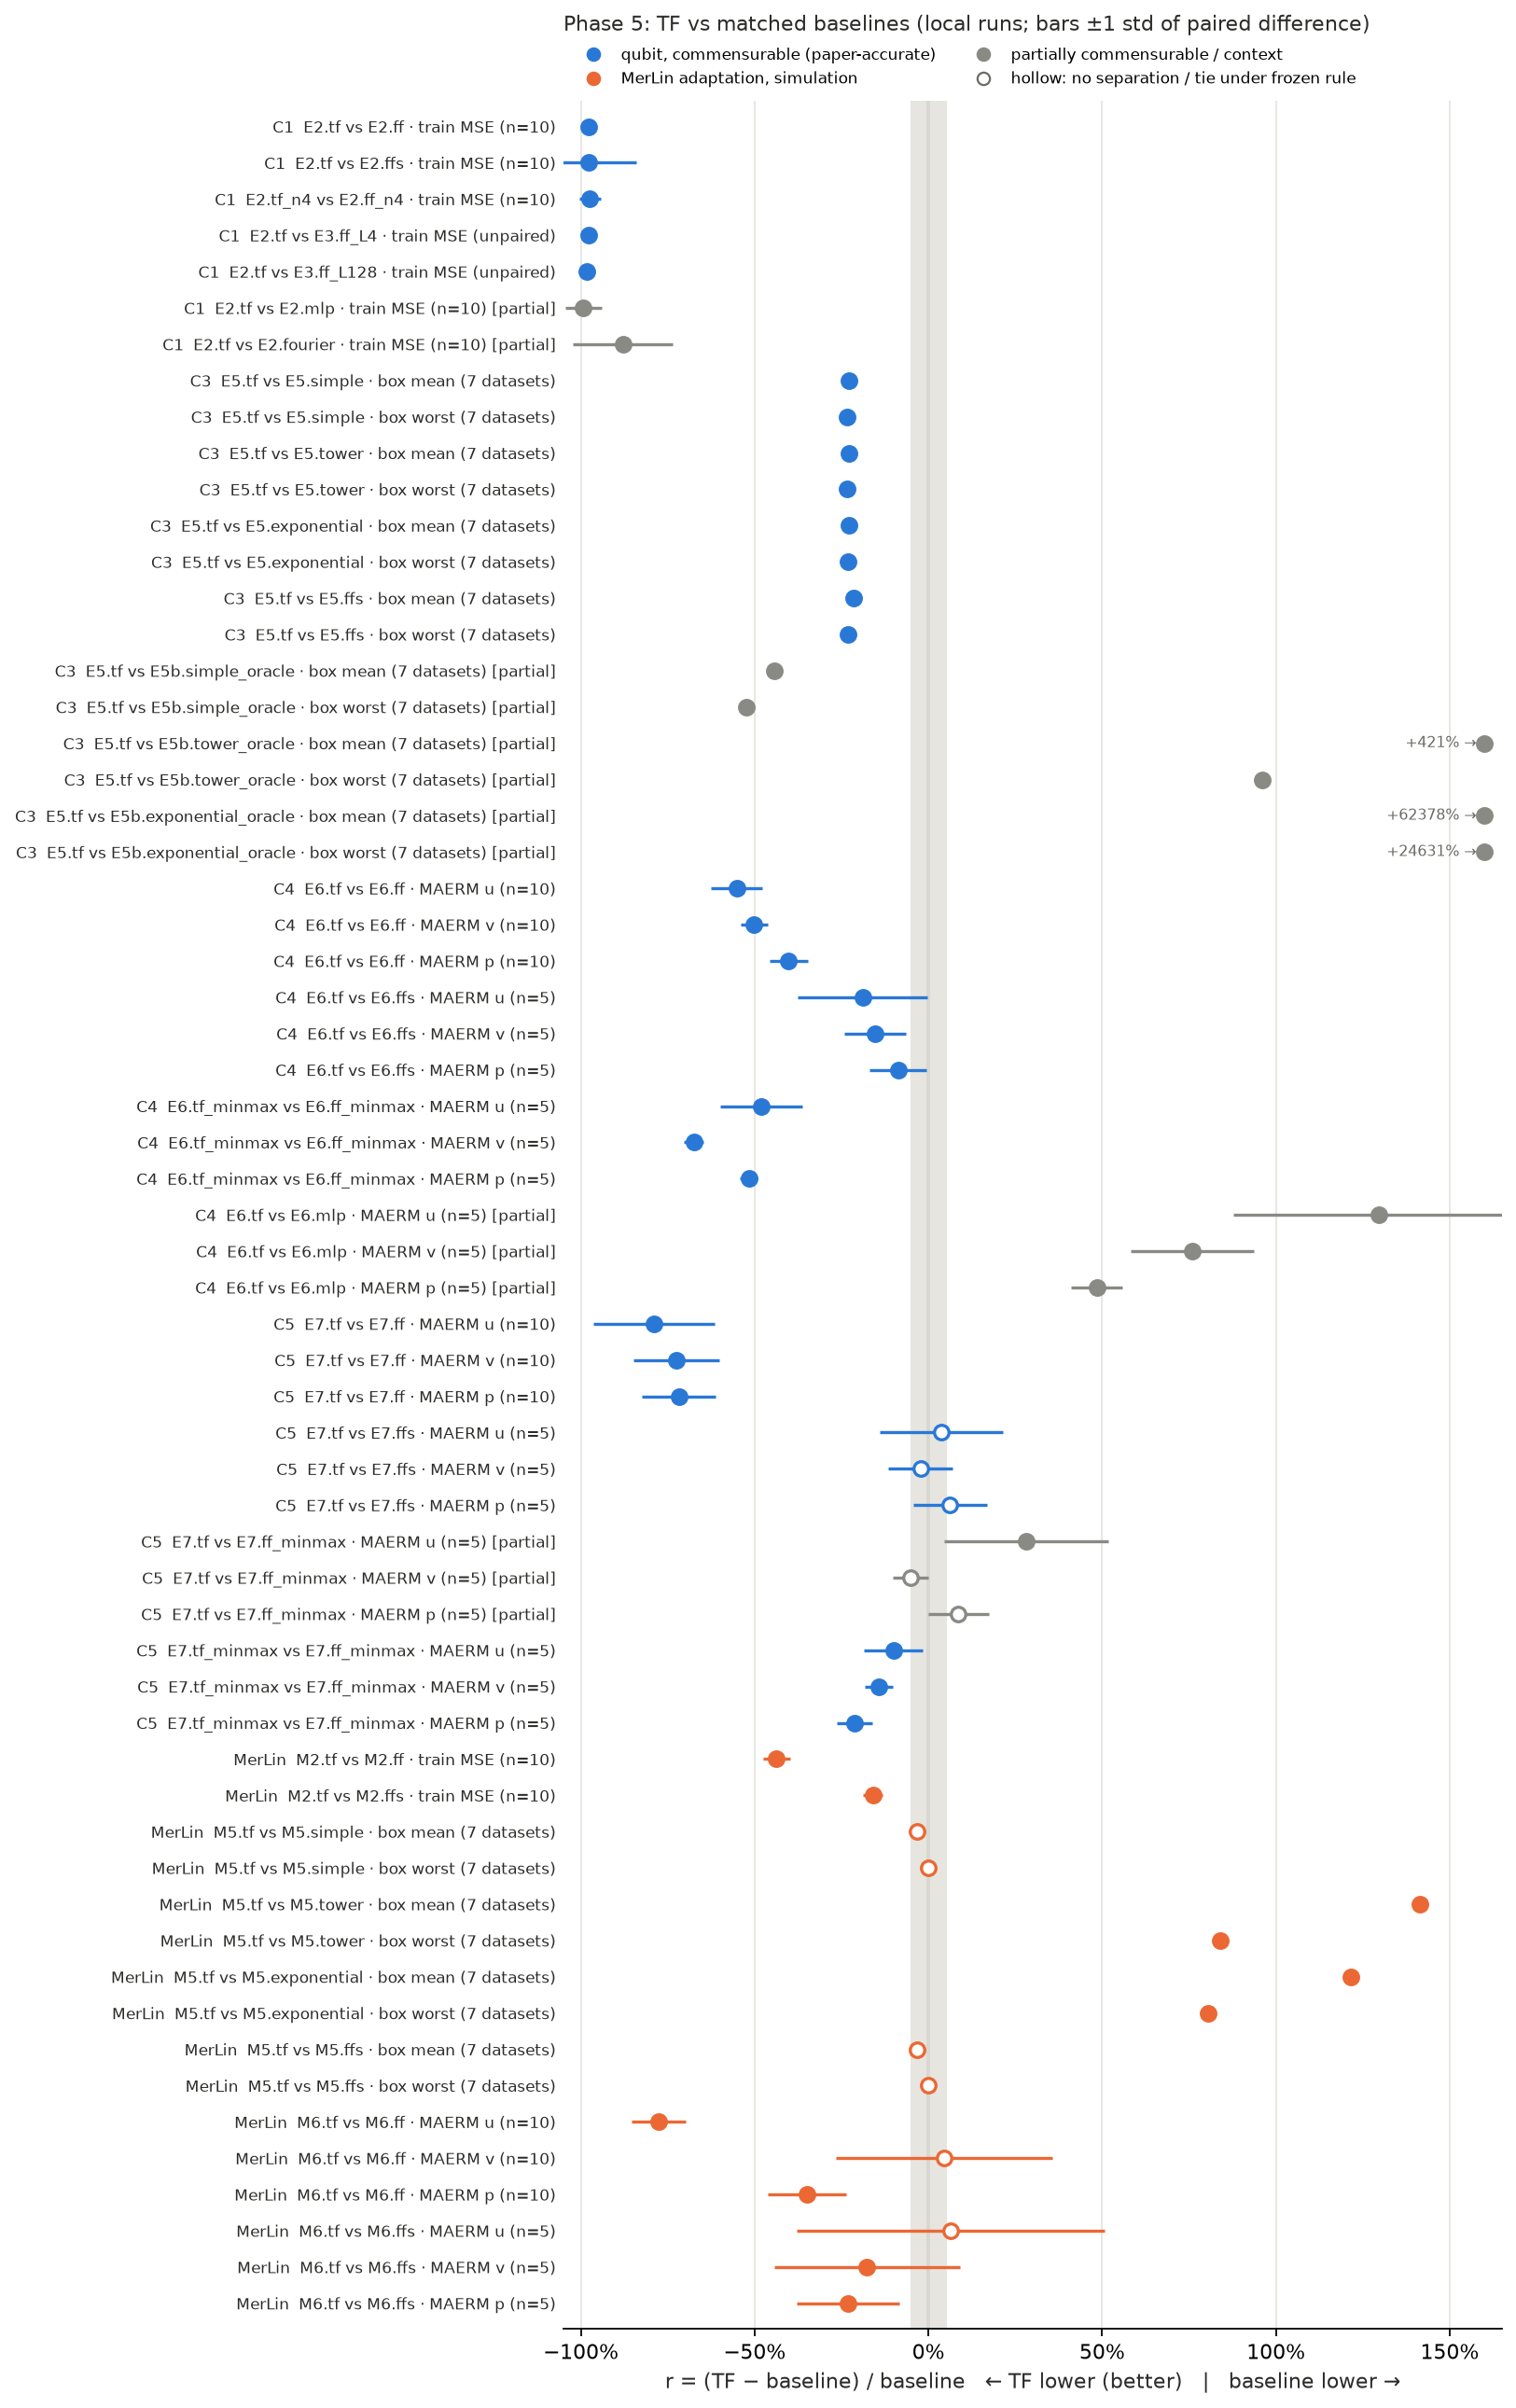

In [15]:
display(Image(filename=str(RESULTS / "p5_comparison_forest.png"), width=820))

**Observation.** Against the paper's FF baseline TF wins everywhere (filled blue dots far left).
Against FF+S, the toy gain stays (−98 %), the Table I gain shrinks to 9–19 % (5/5 seeds,
`consistent`), and the Table II gain disappears (hollow dots, no separation). With min–max
inputs for both models, TF keeps a 10–21 % edge (5/5). The classical MLP PINN is lower than TF
on Navier–Stokes in 5/5 seeds.

**Inference.** Trainable frequencies carry real value when the spectrum is irregular (toy).
On Navier–Stokes, most of the TF gain over the paper's baseline is **input rescaling**, which
3 trainable scale parameters provide just as well.

**Remaining uncertainty.** The controls use 5 seeds (cannot reach $p<0.05$); the paper's own
normalisation is unknown.

**Claim impact.** C1 survives the fair comparison. C4 and C5 are **weakened**: the paper's
baseline is fair for the mechanism but leaves input scale uncontrolled. No quantum-vs-classical
advantage is claimed or observed.

## 9. Controls and ablations  `control`

### 9.1 Depth (Sec. V: "FF never fits, even up to L = 128")

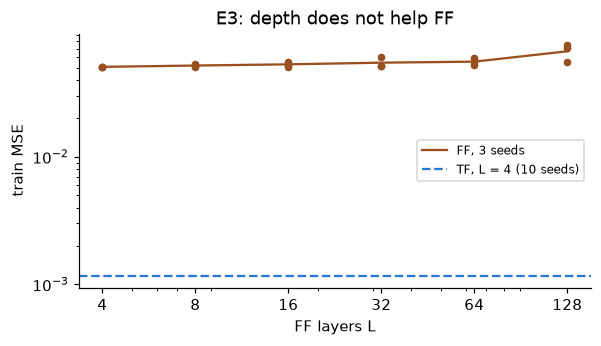

In [16]:
depths = [4, 8, 16, 32, 64, 128]
depth_values = [list(seeds_of("e3_ff_depth", f"ff_L{L}", "train_mse").values()) for L in depths]
fig, ax = plt.subplots(figsize=(6, 3))
for L, values in zip(depths, depth_values):
    ax.scatter([L] * len(values), values, color=COLORS["deep FF"], s=16)
ax.plot(depths, [np.mean(v) for v in depth_values], color=COLORS["deep FF"], label="FF, 3 seeds")
ax.axhline(np.mean(list(e2["TF"].values())), color=COLORS["TF"], ls="--", label="TF, L = 4 (10 seeds)")
ax.set(xscale="log", yscale="log", xlabel="FF layers L", ylabel="train MSE", title="E3: depth does not help FF")
ax.set_xticks(depths, [str(d) for d in depths])
ax.legend(fontsize=8)
plt.show()

### 9.2 Global input scale (Sec. V: "FF with a global scale fits {1.5, 3, 4.5}")

The paper says a global scale suffices when the data are a multiple of the FF spectrum. We
train FF+S and TF on {1.5, 3, 4.5} starting from 1 (the paper's TF initialisation) and from 1.5.

In [17]:
rows = [("start 1", "e4_scaled", {"FF": "ff", "FF+S": "ffs", "TF": "tf"}),
        ("start 1.5", "e4b_scale_init", {"FF (fixed 1.5)": "ff_fixed1.5", "FF+S": "ffs_init1.5", "TF": "tf_init1.5"})]
for start, sweep, candidates in rows:
    for label, key in candidates.items():
        values = list(seeds_of(sweep, key, "train_mse").values())
        print(f"{start:9s} {label:15s} median train MSE {np.median(values):9.2e}   (n = {len(values)})")

start 1   FF              median train MSE  1.13e-01   (n = 10)
start 1   FF+S            median train MSE  1.14e-01   (n = 10)
start 1   TF              median train MSE  1.08e-01   (n = 10)
start 1.5 FF (fixed 1.5)  median train MSE  7.15e-12   (n = 10)
start 1.5 FF+S            median train MSE  2.08e-11   (n = 10)
start 1.5 TF              median train MSE  2.58e-11   (n = 10)


**Observation.** From 1, neither FF+S nor TF finds the scale 1.5 (MSE ≈ 0.11–0.13); started at
1.5, all three fit to ≈ $10^{-11}$. **Inference.** Expressivity is not the problem;
**frequency parameters only move locally under gradient descent** (TF weights also stay within
≈ 0.15 of 1 in §6). **Claim impact (C2).** The statement holds only if the scale starts near the
right value — a caveat the paper does not state.

### 9.3 Spectral richness (Fig. 3)

Seven datasets with $k = 1 \dots 7$ frequencies in $[1, 3]$; 5 seeds each; one box per model over
the 7 seed-averaged errors. We add **E5b**: FF maps whose input is scaled by the data's base
frequency (prior knowledge TF does not get).

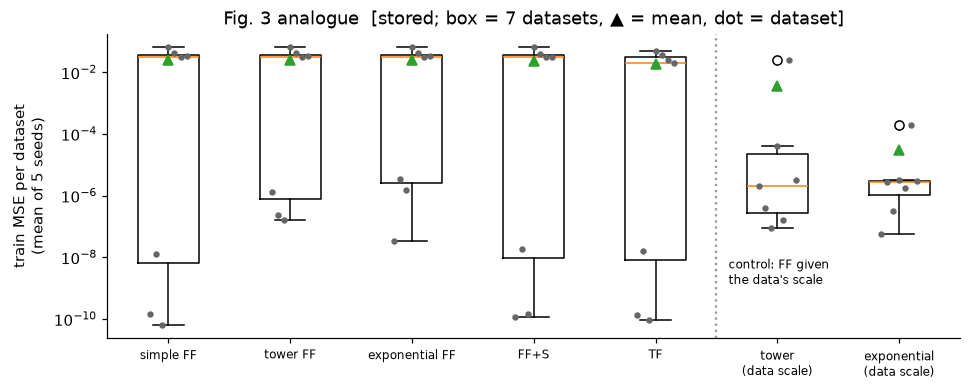

model                             mean     worst      best
simple FF                     2.43e-02  6.41e-02  6.56e-11
tower FF                      2.42e-02  6.41e-02  1.57e-07
exponential FF                2.42e-02  6.40e-02  3.31e-08
FF+S                          2.38e-02  6.39e-02  1.18e-10
TF                            1.87e-02  4.92e-02  9.37e-11
tower FF, data scale          3.59e-03  2.51e-02  8.74e-08
exponential FF, data scale    3.00e-05  1.99e-04  5.51e-08


In [18]:
def fig3_dataset_means(sweep, model):
    return [np.mean(list(seeds_of(sweep, f"{model}_k{k}", "train_mse").values())) for k in range(1, 8)]


fig3 = {name: fig3_dataset_means("e5_fig3", key) for name, key in
        [("simple FF", "simple"), ("tower FF", "tower"), ("exponential FF", "exponential"),
         ("FF+S", "ffs"), ("TF", "tf")]}
fig3_oracle = {f"{m} FF, data scale": fig3_dataset_means("e5b_oracle_scale", f"{m}_oracle")
               for m in ("tower", "exponential")}

fig, ax = plt.subplots(figsize=(10, 3.6))
groups = list(fig3.items()) + list(fig3_oracle.items())
ax.boxplot([v for _, v in groups], showmeans=True, widths=0.5)
for i, (_, values) in enumerate(groups, start=1):
    ax.scatter(np.full(7, i) + np.linspace(-0.15, 0.15, 7), values, s=10, color="0.4", zorder=3)
ax.axvline(5.5, color="0.6", ls=":")
ax.text(5.6, 1e-9, "control: FF given\nthe data's scale", fontsize=8, va="bottom")
ax.set_xticks(range(1, len(groups) + 1), [g.replace(" FF, data scale", "\n(data scale)") for g, _ in groups], fontsize=8)
ax.set(yscale="log", ylabel="train MSE per dataset\n(mean of 5 seeds)", title="Fig. 3 analogue  [stored; box = 7 datasets, ▲ = mean, dot = dataset]")
plt.show()

print(f"{'model':28s} {'mean':>9s} {'worst':>9s} {'best':>9s}")
for name, values in groups:
    print(f"{name:28s} {np.mean(values):9.2e} {np.max(values):9.2e} {np.min(values):9.2e}")

**Observation.** As in the paper, TF has the lowest mean (0.019 vs 0.024) and worst case
(0.049 vs 0.064); best cases tie at the numerical floor (~$10^{-10}$). But the three FF maps
are **identical**: for $k \ge 4$ the data frequencies are non-integer, which no integer-gap map
can represent, so the paper's "too few / too many frequencies" story does not appear. It
appears only with the data-scaled FF (right of the dotted line), and then **exponential FF beats
TF by orders of magnitude**.

**Inference.** TF helps when the right input scale is unknown; it does not beat a well-scaled
FF feature map. **Claim impact (C3).** Ranking reproduced, mechanism not; partially supported.

### 9.4 Navier–Stokes: is the TF gain an input-scaling effect?

Diagnosis of the Table II FF gap (single seed, `preliminary`): 15 000 instead of 5000 iterations
barely help (plateau), while min–max inputs or 3 trainable scales (FF+S) bring FF to TF level.
The multi-seed controls:

In [19]:
controls = {
    "Table I": [("FF", "e6_table1", "ff"), ("FF+S", "e6_controls", "ffs"), ("TF", "e6_table1", "tf"),
                ("FF min–max", "e6_minmax", "ff_minmax"), ("TF min–max", "e6_minmax", "tf_minmax"),
                ("MLP PINN (context)", "e6_controls", "mlp_lr1e-2")],
    "Table II": [("FF", "e7_appc", "ff"), ("FF+S", "e7_scaling_controls", "ffs"),
                 ("TF", "e7_appc_retry+e7_appc", "tf"),
                 ("FF min–max", "e7_scaling_controls", "ff_minmax"), ("TF min–max", "e7_scaling_controls", "tf_minmax")],
}
for table, rows in controls.items():
    print(f"{table}: mean MAERM % u / v / p (± std over seeds)")
    for label, sweep, key in rows:
        values = [list(ns_seeds(sweep, key, f).values()) for f in "uvp"]
        cells = " / ".join(f"{np.mean(v):6.1f}±{np.std(v, ddof=1):4.1f}" for v in values)
        print(f"   {label:20s} {cells}   n = {len(values[0])}")

print("\nPaired TF vs control (same seeds):")
for table, a, b in [("Table I", ("e6_table1", "tf"), ("e6_controls", "ffs")),
                    ("Table II", ("e7_appc_retry+e7_appc", "tf"), ("e7_scaling_controls", "ffs")),
                    ("Table II", ("e7_scaling_controls", "tf_minmax"), ("e7_scaling_controls", "ff_minmax"))]:
    for field in "uvp":
        r = paired(ns_seeds(*a, field), ns_seeds(*b, field))
        print(f"   {table:8s} {a[1]:10s} vs {b[1]:10s} {field}: {r['mean_a']:6.1f} vs {r['mean_b']:6.1f}, "
              f"lower {r['a_lower']}/{r['n']}, p = {r['wilcoxon_p']:.3f}")

Table I: mean MAERM % u / v / p (± std over seeds)
   FF                     20.1± 0.9 /   61.0± 1.8 /   76.2± 3.5   n = 10
   FF+S                   11.2± 1.5 /   35.6± 2.9 /   49.9± 5.6   n = 5
   TF                      9.0± 1.4 /   30.4± 3.5 /   45.6± 3.6   n = 10
   FF min–max             14.6± 0.3 /   87.7± 2.7 /   86.4± 2.9   n = 5
   TF min–max              7.6± 1.4 /   28.5± 1.6 /   41.8± 1.8   n = 5
   MLP PINN (context)      4.0± 0.3 /   17.1± 1.5 /   30.7± 4.0   n = 5
Table II: mean MAERM % u / v / p (± std over seeds)
   FF                     31.5± 5.4 /   73.2± 8.7 /  123.3±13.0   n = 10
   FF+S                    6.1± 0.6 /   20.6± 1.3 /   32.4± 2.6   n = 5
   TF                      6.6± 0.9 /   20.1± 1.3 /   34.8± 2.6   n = 10
   FF min–max              4.9± 0.3 /   21.2± 0.8 /   31.7± 1.9   n = 5
   TF min–max              4.4± 0.5 /   18.2± 1.1 /   25.0± 2.0   n = 5

Paired TF vs control (same seeds):
   Table I  tf         vs ffs        u:    9.1 vs   11.2, lower 5

**Observation.** FF+S (3 extra parameters per network instead of TF's 6 or 12) recovers most of
the Table I gap and all of the Table II gap (TF vs FF+S: 2–3/5 seeds, $p > 0.3$). With min–max
inputs for both, TF stays lower in 5/5 seeds by 10–21 %. A small classical PINN is better than
every quantum model.

**Inference.** The paper-style Navier–Stokes advantage of TF over FF is mostly an input-scaling
effect; a smaller, consistent per-gate-frequency benefit remains once inputs are scaled.

**Remaining uncertainty.** 5 seeds per control; one normalisation scheme (min–max) tested.

**Claim impact (C4, C5).** Partially supported.

## 10. Robustness and uncertainty

### 10.1 Learning rate (`preliminary`, 3 seeds per lr)
The paper uses one learning rate. Our predeclared check reruns Fig. 2b and Fig. 3 at
lr ∈ {1e-3, 3e-3, 1e-2}.

In [20]:
def fig2b_values(model, lr):
    # lr 1e-3 comes from the main sweep (seeds 1-3 to match), the others from lr_robustness.
    if lr == "1e-3":
        return [seeds_of("e2_fig2b", model, "train_mse")[s] for s in (1, 2, 3)]
    return list(seeds_of("lr_robustness", f"e2_{model}_lr{lr}", "train_mse").values())


def fig3_worst_case(model, lr):
    # Worst dataset of the Fig. 3 box: max over k of the 3-seed mean train MSE.
    if lr == "1e-3":
        return max(np.mean([seeds_of("e5_fig3", f"{model}_k{k}", "train_mse")[s] for s in (1, 2, 3)])
                   for k in range(1, 8))
    return max(np.mean(list(seeds_of("lr_robustness", f"e5_{model}_k{k}_lr{lr}", "train_mse").values()))
               for k in range(1, 8))


print(f"{'lr':6s} {'Fig. 2b TF / FF (mean, 3 seeds)':>34s} {'Fig. 3 worst case: TF vs best FF':>36s}")
for lr in ("1e-3", "3e-3", "1e-2"):
    best_ff = min(fig3_worst_case(m, lr) for m in ("simple", "tower", "exponential"))
    print(f"{lr:6s} {np.mean(fig2b_values('tf', lr)):14.2e} / {np.mean(fig2b_values('ff', lr)):9.2e}"
          f"           {fig3_worst_case('tf', lr):9.3f} vs {best_ff:9.3f}")

lr        Fig. 2b TF / FF (mean, 3 seeds)     Fig. 3 worst case: TF vs best FF
1e-3         5.54e-04 /  5.06e-02               0.040 vs     0.064
3e-3         6.43e-04 /  5.32e-02               0.038 vs     0.066
1e-2         1.98e-03 /  5.42e-02               0.109 vs     0.074


**Observation.** On Fig. 2b TF beats FF by ≈ 25–90× at every lr. On Fig. 3, at lr $10^{-2}$
TF's worst case (0.109) is **worse** than every FF map (≈ 0.074). **Claim impact (C7).** "TF is
never worse than FF" holds at the paper's lr, not universally.

### 10.2 Seed variability
Every comparison above shows individual seeds. TF's spread is larger than FF's (e.g. Fig. 2b TF
MSE spans $2\cdot10^{-5}$–$5\cdot10^{-3}$ over 10 seeds): trainable frequencies add optimisation variance. With
5 seeds the Wilcoxon test cannot reach $p<0.05$, so those results are reported as consistent
signs.

### 10.3 Cost (claim C6)

In [21]:
for label, sweep in [("Table I (same launch, L4 host, 4 workers)", "e6_table1")]:
    tf_s = np.mean(list(seeds_of(sweep, "tf", "seconds_per_iteration").values()))
    ff_s = np.mean(list(seeds_of(sweep, "ff", "seconds_per_iteration").values()))
    c_f = next(iter(PER_SEED[sweep]["candidates"]["tf"].values()))["cost_factor"]
    print(f"{label}: TF {tf_s:.3f} s/it vs FF {ff_s:.3f} s/it (×{tf_s / ff_s:.3f}); "
          f"C_f = (θ_F + θ_A) / θ_A = {c_f:.4f}  (paper: 1.07)")

Table I (same launch, L4 host, 4 workers): TF 0.243 s/it vs FF 0.233 s/it (×1.043); C_f = (θ_F + θ_A) / θ_A = 1.0333  (paper: 1.07)


The paper divides 12 frequency parameters by the 180 ansatz parameters of **one** network; both
networks have 180, so $C_f = (12 + 360)/360 = 1.033$. Measured wall-clock overhead: +4 %.
**Claim impact (C6).** Supported, with a corrected number.

## 11. Photonic (MerLin) adaptation  `adaptation`

The paper is gate-based. Photonics has a natural counterpart: a **phase shifter**
$e^{i\varphi \hat n}$ with $\varphi = \gamma\, w\, x$ on a mode multiplies each Fock component by
$e^{i n \varphi}$, so the output is a Fourier series whose frequencies are **photon-number
differences times $\gamma w$**: integers for FF ($w = 1$), learnable for TF ($w$ trainable).

Our model (`lib/qnn_merlin.py`): trainable MZI mesh → phase-shifter encoding on 3 of 6 modes
(3 photons, input $|1,0,1,0,1,0\rangle$) → mesh. Readout: threshold detectors **without
post-selection**, as the fixed observable (#clicks on even modes − #clicks on odd modes),
analogous to $\sum Z$. Simulated exactly with MerLin (lossless, noiseless, no QPU).

### 11.1 The readout decides the spectrum (live)

threshold_clicks : accessible gaps [1.0, 2.0, 3.0], max power above ω = 3.5: 3.3e-06


unbunched_clicks : accessible gaps [1.0, 2.0, 3.0], max power above ω = 3.5: 5.1e-04


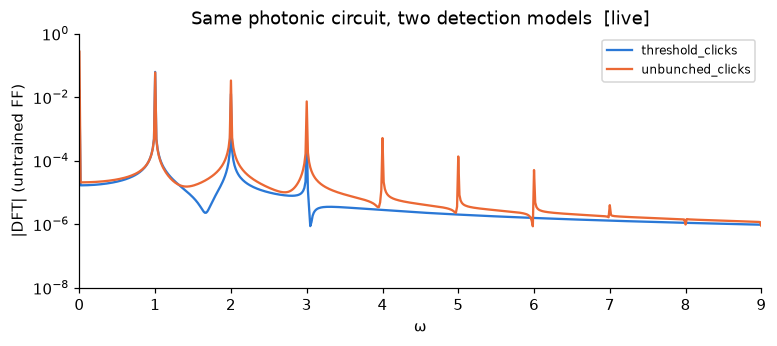

In [22]:
def photonic(readout, mode="fixed", seed=3):
    return PhotonicFrequencyModel(n_modes=6, n_photons=3, n_inputs=1, layout="toy",
                                  encoding_modes_per_input=3, feature_map="simple", frequency_mode=mode,
                                  frequency_init=1.0, readout=readout, dtype=dtype,
                                  generator=torch.Generator().manual_seed(seed))


fig, ax = plt.subplots(figsize=(8, 3))
for readout, color in [("threshold_clicks", COLORS["TF"]), ("unbunched_clicks", COLORS["FF"])]:
    model = photonic(readout)
    angular, magnitude = prediction_spectrum(model, 64, 8192, dtype, "cpu")
    ax.semilogy(angular, magnitude + 1e-12, color=color, label=readout)
    print(f"{readout:17s}: accessible gaps {model.accessible_frequencies()}, "
          f"max power above ω = 3.5: {magnitude[angular > 3.5].max():.1e}")
ax.set(xlim=(0, 9), ylim=(1e-8, 1), xlabel="ω", ylabel="|DFT| (untrained FF)",
       title="Same photonic circuit, two detection models  [live]")
ax.legend(fontsize=8)
plt.show()

Threshold detection keeps the finite spectrum {1, 2, 3}. MerLin's default `UNBUNCHED` space
post-selects collision-free events and renormalises, which turns the output into a *ratio* of
Fourier series and leaks power to ω = 4…8. Spectrum claims therefore require the
non-post-selected readout (we report UNBUNCHED only as an ablation).

### 11.2 Fig. 2b in photonics (live seed 1 + stored 10 seeds)

In [23]:
started = time.perf_counter()
live_photonic = {name: run_live(overlay, f"m2_{name}_seed1", seed=1)
                 for name, overlay in [("FF", "fig2b_ff_merlin.json"), ("TF", "fig2b_tf_merlin.json")]}
print(f"2 photonic runs (6000 iterations each) in {time.perf_counter() - started:.0f} s")
for name, key in [("FF", "ff"), ("TF", "tf")]:
    stored = seeds_of("m2_fig2b", key, "train_mse")
    print(f"{name}: live seed 1 = {live_photonic[name]['train_mse']:.4e}, stored seed 1 = {stored[1]:.4e}, "
          f"stored mean over 10 seeds = {np.mean(list(stored.values())):.4f}")
    assert abs(live_photonic[name]["train_mse"] / stored[1] - 1) < 1e-6

m2 = {label: seeds_of("m2_fig2b", key, "train_mse") for label, key in [("FF", "ff"), ("FF+S", "ffs"), ("TF", "tf")]}
for name in ("FF", "FF+S"):
    r = paired(m2["TF"], m2[name])
    print(f"photonic TF vs {name}: {r['mean_a']:.3f} vs {r['mean_b']:.3f}, lower {r['a_lower']}/{r['n']}, "
          f"p = {r['wilcoxon_p']:.3f}")
print(f"qubit TF / FF ratio: {np.mean(list(e2['TF'].values())) / np.mean(list(e2['FF'].values())):.3f}; "
      f"photonic: {np.mean(list(m2['TF'].values())) / np.mean(list(m2['FF'].values())):.2f}")

2 photonic runs (6000 iterations each) in 82 s
FF: live seed 1 = 1.0255e-01, stored seed 1 = 1.0255e-01, stored mean over 10 seeds = 0.1005
TF: live seed 1 = 5.6026e-02, stored seed 1 = 5.6026e-02, stored mean over 10 seeds = 0.0566
photonic TF vs FF: 0.057 vs 0.101, lower 10/10, p = 0.002
photonic TF vs FF+S: 0.057 vs 0.067, lower 10/10, p = 0.002
qubit TF / FF ratio: 0.023; photonic: 0.56


### 11.3 Where the photonic version differs (stored)

In [24]:
m5 = {name: fig3_dataset_means("m5_fig3", key) for name, key in
      [("simple", "simple"), ("tower", "tower"), ("exponential", "exponential"), ("FF+S", "ffs"), ("TF", "tf")]}
print("Photonic Fig. 3 (4 photons / 8 modes): mean / worst over 7 datasets")
for name, values in m5.items():
    print(f"   {name:12s} {np.mean(values):.4f} / {np.max(values):.4f}")
m6 = {label: [np.mean(list(seeds_of(f"m6_table1_{key}", key, f"{f}_mean_maerm").values())) for f in "uvp"]
      for label, key in [("FF", "ff"), ("FF+S", "ffs"), ("TF", "tf")]}
print("Photonic Table I, mean MAERM % u / v / p:")
for label, values in m6.items():
    print(f"   {label:5s} " + " / ".join(f"{v:6.1f}" for v in values))

hardware = json.loads((RESULTS / "merlin_hardware_report.json").read_text())
row = next(r for r in hardware if r["sweep"] == "m2_fig2b" and r["candidate"] == "tf")
print("\nHardware-aware settings (m2_fig2b, TF):")
for key in ("computation_space", "detector_model", "photons", "modes", "input_state", "postselection", "shots", "simulator_or_qpu"):
    print(f"   {key:18s} {row[key]}")

Photonic Fig. 3 (4 photons / 8 modes): mean / worst over 7 datasets
   simple       0.0605 / 0.1173
   tower        0.0242 / 0.0637
   exponential  0.0264 / 0.0649
   FF+S         0.0605 / 0.1173
   TF           0.0585 / 0.1172
Photonic Table I, mean MAERM % u / v / p:
   FF      96.8 /   90.8 /  124.8
   FF+S    22.6 /  113.2 /  105.1
   TF      21.7 /   94.9 /   81.2

Hardware-aware settings (m2_fig2b, TF):
   computation_space  FOCK (simulated)
   detector_model     threshold, no post-selection
   photons            3
   modes              6
   input_state        [1, 0, 1, 0, 1, 0]
   postselection      none
   shots              n/a (exact probabilities, shots = 0)
   simulator_or_qpu   MerLin analytic simulator (merlin 0.4.1), local CPU (Apple M3), 6 workers


(The stored report prints `merlin 0.4.1` because the package reports that version string; the
installed distribution is `merlinquantum` 0.4.2 — reported to the MerLin team.)

**Observation.** Photonic TF beats photonic FF and FF+S on irregular frequencies (10/10), but
the gain is much weaker than with qubits (TF/FF 0.56 vs 0.02). On Fig. 3 the ranking
**inverts**: tower and exponential FF beat TF. On Navier–Stokes, photonic TF beats FF on u and
p, not on v, and all photonic errors are far above the qubit ones.

**Inference.** With $\gamma = 1$, frequency 3 needs all three photons in the encoding modes in
superposition with none there (a NOON-like component), which a linear mesh on single photons
prepares only weakly: its coefficient stays near 0.05 instead of 0.33 (Phase 4 diagnosis).
Tower / exponential maps put high frequencies on **one** photon through a large-$\gamma$ mode and
avoid this cap. TF starts as the simple map and only moves locally (§9.2), so it inherits the cap.

**Remaining uncertainty.** One architecture (mesh–encode–mesh, spread input state); other input
states or deeper re-uploading may lift the cap. Simulation only.

**Claim impact.** The mechanism transfers to photonics; the "sensible default" argument does
not. This is an adaptation and does not count for or against the paper's reproduction.

## 12. Limitations, reductions and deviations

| Item | What we did | Likely impact |
|---|---|---|
| Simulator | Own PyTorch statevector simulator, exact, autograd instead of parameter-shift | None in noiseless simulation (identical derivatives) |
| Noise | Noiseless, like the paper; no shots, no hardware | Results say nothing about NISQ execution |
| Qubits for Fig. 2 | N = 3 (text and appendix disagree; N = 4 also run, same conclusion) | None on the claim |
| NS input normalisation | Raw coordinates by default (paper silent); min–max variant run | Changes FF error up to 4×; decisive for C4/C5 |
| NS batch composition, sub-grid placement | 600 data + 600 collocation points per iteration (paper ambiguous) | Likely explains our better-than-paper TF numbers |
| App. C layout | 67 layers inferred from the 804-parameter count | Low (TF matches Table II) |
| Seeds | Controls: 5 seeds (cannot reach p < 0.05); depth and lr: 3 (`preliminary`) | Control results are consistent signs, not significance |
| Live vs stored | Live: Fig. 2b seeds 1–3, NS smoke (3 iterations), photonic spectrum + 2 runs. Everything else loaded from stored runs | Live runs reproduce stored values to < 1e-6 |
| Toy tasks | No held-out split | They test representation, not generalisation |
| Photonic | One architecture; 3–4 photons; simulation only; depth (E3) and App. C (E7) not translated | Photonic conclusions may depend on the architecture |

What each layer of evidence shows, kept separate:
* **The software executes:** §4, §6, §7.2 smoke, §11 (live).
* **The method solves the task:** TF fits {1, 1.2, 3} (§6–7.1); NS errors of 9–45 % (§7.2).
* **The paper's metric reproduces:** TF Tables I–II yes (v exact); FF no (§7.2).
* **The paper's explanation survives controls:** toy yes (§7.1, §9.1); NS mostly no (§9.4); Fig. 3 partly (§9.3).
* **The method beats a fair baseline:** paper baseline yes; FF+S yes on toy, marginal / no on NS; classical PINN no (§8).

## 13. Conclusion

**1. What reproduced**
* C1: FF cannot fit {1, 1.2, 3}, TF can, with learned weights like the paper's — quantitatively, 10/10 seeds, robust to depth, a global scale and learning rate (§6, §7.1, §9.1, §10.1).
* C2: FF fits its own frequencies {1, 2, 3} (§4, stored E1: median MSE 6e-3 for N = 3, 4e-4 for N = 4).
* The TF numbers of Tables I and II (§7.2) and the TF > FF ranking in every Navier–Stokes field (§7.2).
* C6, with a corrected cost factor of 1.033 (§10.3).

**2. What did not reproduce**
* The FF numbers of Tables I and II (our raw-input FF is worse; §7.2, §9.4).
* The Fig. 3 mechanism: the three FF maps are identical on non-integer data (§9.3).
* "A global scale suffices" for {1.5, 3, 4.5} unless the scale starts near 1.5 (§9.2).

**3. What remains unresolved**
* The paper's Navier–Stokes input normalisation and batch composition, hence its exact FF baseline (§7.2, §12).
* Whether the 10–21 % TF edge with normalised inputs is significant (5 seeds; §9.4).

**4. What was not attempted**
* Noisy or hardware execution; other PDEs; photonic versions of the depth ablation and App. C (§12).

**5. Reproduction verdict — partially reproduced.**
C1 supported; C2 supported with a caveat; C3, C4, C5 and C7 partially supported (the
Navier–Stokes and Fig. 3 gains shrink or vanish against input-scaling controls; TF can be worse
at a higher lr); C6 supported with a correction. No quantum advantage over classical models is
claimed by the paper or supported here (§8).

**6. Photonic verdict — adaptation, `MERLIN_IMPLEMENTATION`.**
The FF / TF mechanism maps naturally to phase-shifter encodings and TF beats FF on irregular
frequencies, but multi-photon coefficient limits make well-chosen fixed encodings (tower,
exponential) better than TF on Fig. 3; the readout must avoid post-selection to keep the spectrum
(§11).

Further reading: `README.md` (full tables), `INSIGHTS.md` (lessons),
`results/p5_comparison.md` (frozen comparison).